# Assignment 5: Ensemble Learning in Classification
## Stacking, AdaBoost and Voting on the Breast Cancer Wisconsin (Diagnostic) dataset

**NAME: Parth Iskear**     **PRN:202401080062**

**Aim:** Build stacking, AdaBoost and voting ensembles, compare them against the individual base classifiers, and decide when each ensemble method is worth using.

**Dataset choice:** Breast Cancer Wisconsin (Diagnostic), shipped with scikit-learn. It has 569 samples, 30 numeric features computed from digitised images of fine needle aspirates, and a binary target (malignant or benign). It was chosen because it is a real, well known classification problem, it is slightly imbalanced (so accuracy alone is not enough), its features are strongly correlated (a real preprocessing task), and it loads offline so the notebook runs anywhere.

## 1. Imports and setup

In [1]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier, StackingClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42
sns.set_style("whitegrid")

## 2. Data loading and exploration

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
print("Shape:", df.shape)
print("Target mapping:", dict(zip(range(2), data.target_names)))
df.head()

Shape: (569, 31)
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [4]:
df.describe().T.head(12)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


## 3. Data preprocessing

Steps followed: check missing values and duplicates, inspect class balance, inspect outliers, remove redundant (highly correlated) features, stratified train/test split, and feature scaling.

### 3.1 Missing values and duplicates

In [5]:
print("Total missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Total missing values: 0
Duplicate rows: 0


No missing values and no duplicate rows, so no imputation or row removal is needed.

### 3.2 Class balance

target
benign       357
malignant    212
Name: count, dtype: int64
target
benign       62.7 %
malignant    37.3 %
Name: count, dtype: str


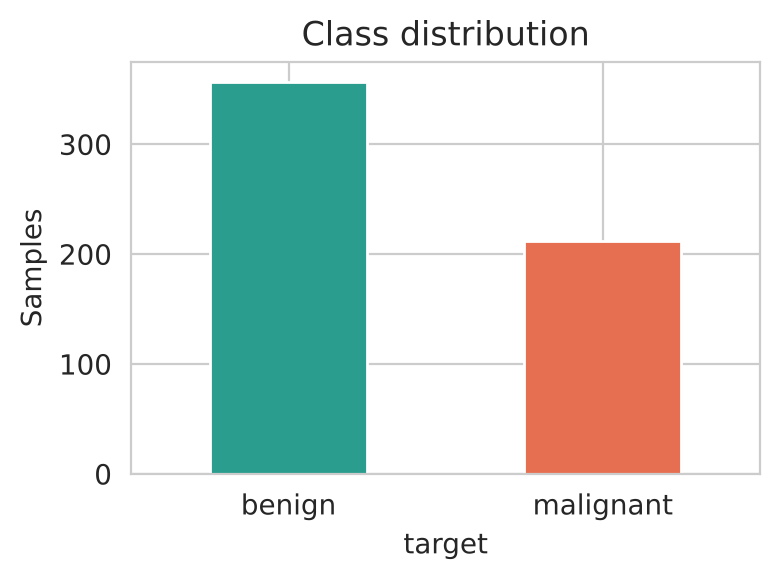

In [6]:
counts = df["target"].value_counts().rename(index={0: "malignant", 1: "benign"})
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")
counts.plot(kind="bar", color=["#2a9d8f", "#e76f51"], figsize=(4, 3), title="Class distribution")
plt.ylabel("Samples"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

The split is roughly 63% benign and 37% malignant. It is mildly imbalanced, so a stratified split is used and precision, recall, F1 and ROC-AUC are reported alongside accuracy.

### 3.3 Outliers

In [7]:
X_all = df.drop(columns="target")
q1, q3 = X_all.quantile(0.25), X_all.quantile(0.75)
iqr = q3 - q1
outlier_counts = ((X_all < q1 - 1.5 * iqr) | (X_all > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
print("Features with the most IQR outliers:")
print(outlier_counts.head(8))

Features with the most IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
dtype: int64


Several features have IQR outliers. They are **kept**, because in this dataset extreme values usually belong to genuinely large malignant tumours and removing them would delete the signal we want to detect. Instead, `StandardScaler` is used and the tree based models and the SVM/logistic models are left to cope with them.

### 3.4 Removing redundant features

Features dropped (|corr| > 0.95): 7
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


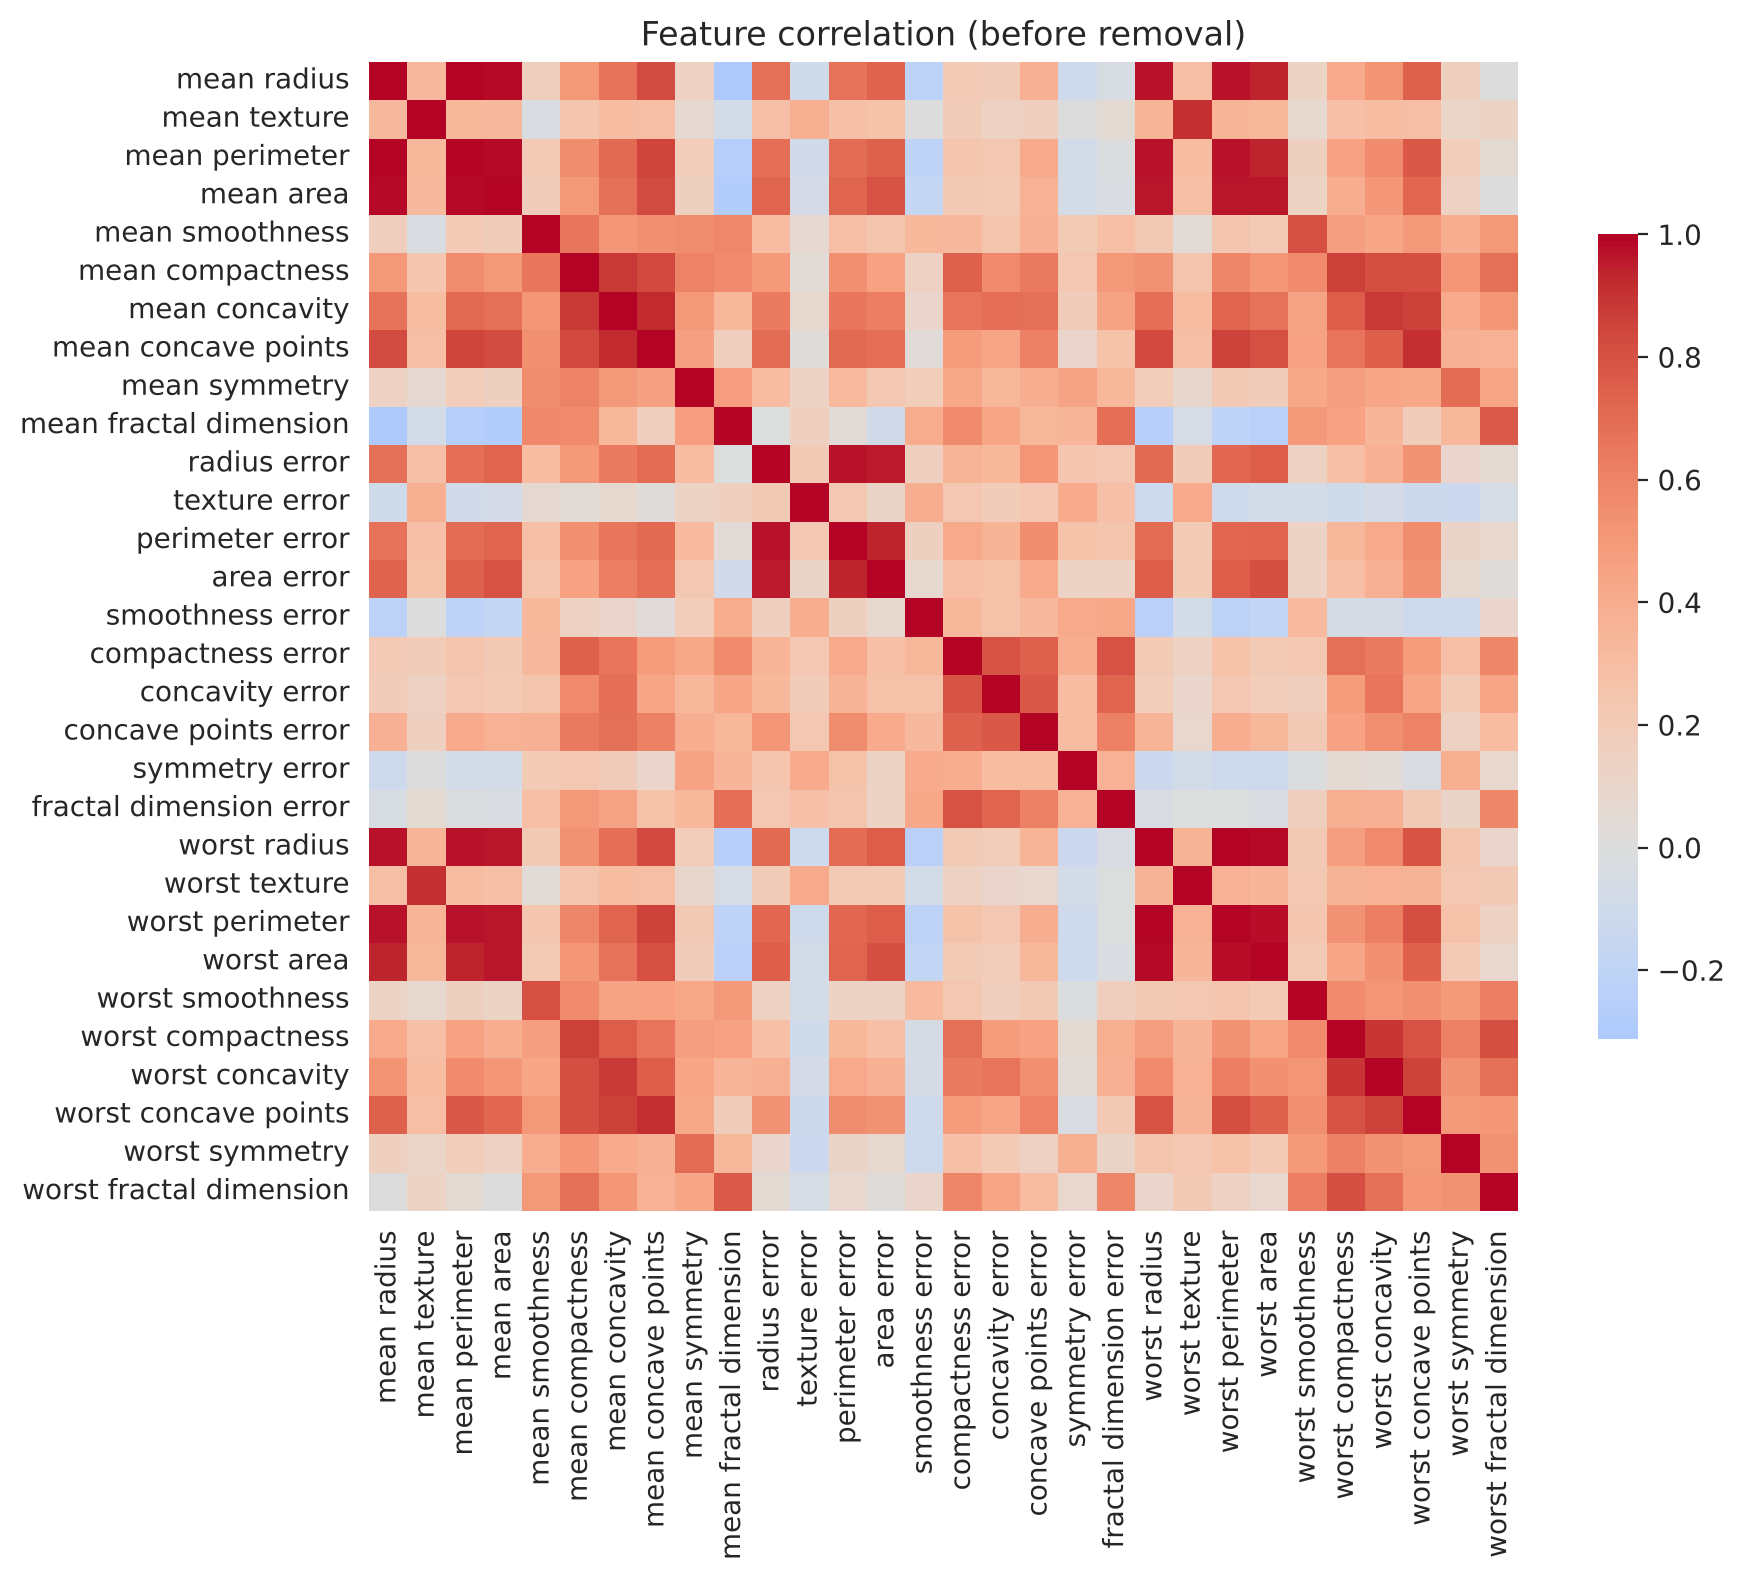

Remaining features: 23


In [8]:
X = df.drop(columns="target")
y = df["target"]

corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
print(f"Features dropped (|corr| > 0.95): {len(to_drop)}")
print(to_drop)

plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation (before removal)")
plt.tight_layout(); plt.show()

X = X.drop(columns=to_drop)
print("Remaining features:", X.shape[1])

Pairs such as radius, perimeter and area are almost perfectly correlated. Keeping all of them adds no information and makes the ensemble members look more alike, which hurts diversity. One feature of each highly correlated pair was removed.

### 3.5 Train/test split and scaling

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), " Test class ratio:", y_test.mean().round(3))

Train: (455, 23)  Test: (114, 23)
Train class ratio: 0.626  Test class ratio: 0.632


Scaling is placed **inside each model pipeline** (`StandardScaler` followed by the classifier). This way the scaler is fitted only on training data in every fit and every cross-validation fold, so no test information leaks into training. Distance and margin based models (KNN, SVM, logistic regression) need scaling; trees are unaffected by it.

## 4. Base classifiers

Five different model families are used so that their errors are not identical, which is what ensembles need.

- Logistic Regression: linear model
- KNN: distance based, local decision boundary
- SVM (RBF kernel): margin based, non-linear
- Decision Tree (max depth 4): rule based, high variance
- Gaussian Naive Bayes: probabilistic with a strong independence assumption

In [10]:
def lr():  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
def knn(): return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))
def svm(): return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE))
def dt():  return DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
def nb():  return make_pipeline(StandardScaler(), GaussianNB())

base_models = {
    "Logistic Regression": lr(),
    "KNN": knn(),
    "SVM": svm(),
    "Decision Tree": dt(),
    "Naive Bayes": nb(),
}

## 5. Ensemble models

### 5.1 Voting ensemble (majority voting)
Each base classifier casts one vote and the class with the most votes wins (`voting="hard"`). Five voters are used so ties cannot occur in a binary problem. A soft voting version (average of predicted probabilities) is added as an extra comparison.

In [11]:
estimators = [("lr", lr()), ("knn", knn()), ("svm", svm()), ("dt", dt()), ("nb", nb())]

voting_hard = VotingClassifier(estimators=estimators, voting="hard")
voting_soft = VotingClassifier(estimators=estimators, voting="soft")

### 5.2 Stacking ensemble
The base classifiers are trained first. Their out-of-fold predicted probabilities (`cv=5`) become the input features of a **Logistic Regression meta-classifier**, which learns how much to trust each base model. Out-of-fold predictions are important: if the meta-classifier were trained on predictions the base models made on their own training data, it would be fed over-confident outputs.

In [12]:
stack_estimators = [("knn", knn()), ("svm", svm()), ("dt", dt()), ("nb", nb())]

stacking = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    cv=5, stack_method="predict_proba", n_jobs=-1)

### 5.3 AdaBoost ensemble
AdaBoost trains weak learners one after another and increases the weight of samples the previous learner got wrong. Two base learners are tried: a decision stump (depth 1, the classic choice) and a depth 2 tree. A third, logistic regression, is included to show how a stable linear learner behaves under boosting.

In [13]:
ada_stump = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200,
                               learning_rate=0.5, random_state=RANDOM_STATE)
ada_depth2 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=200,
                                learning_rate=0.5, random_state=RANDOM_STATE)
ada_lr = make_pipeline(StandardScaler(),
                       AdaBoostClassifier(estimator=LogisticRegression(max_iter=2000), n_estimators=50, random_state=RANDOM_STATE))

Effect of the number of boosting rounds on test accuracy for the stump based AdaBoost:

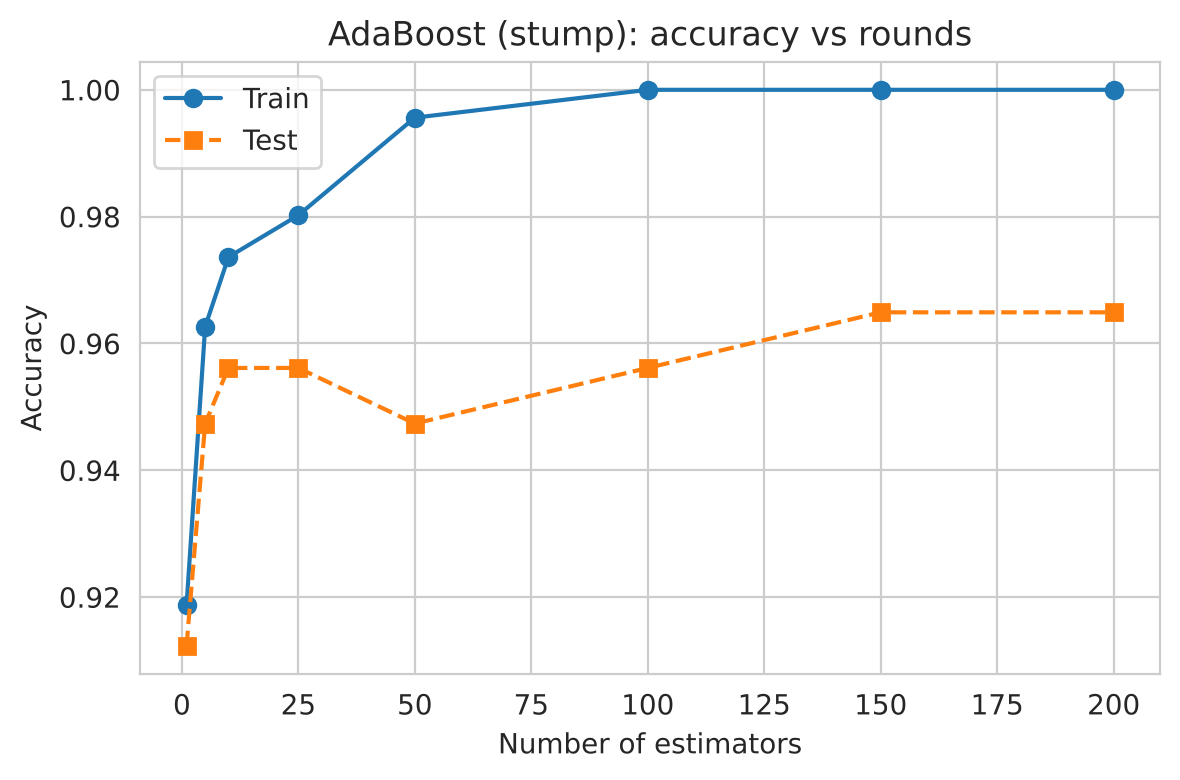

 n_estimators  train_acc  test_acc
            1     0.9187    0.9123
            5     0.9626    0.9474
           10     0.9736    0.9561
           25     0.9802    0.9561
           50     0.9956    0.9474
          100     1.0000    0.9561
          150     1.0000    0.9649
          200     1.0000    0.9649


In [14]:
n_list = [1, 5, 10, 25, 50, 100, 150, 200]
train_acc, test_acc = [], []
for n in n_list:
    m = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=n,
                           learning_rate=0.5, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train)); test_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(6, 4))
plt.plot(n_list, train_acc, marker="o", color="#1f77b4", label="Train")
plt.plot(n_list, test_acc, marker="s", color="#ff7f0e", linestyle="--", label="Test")
plt.xlabel("Number of estimators"); plt.ylabel("Accuracy")
plt.title("AdaBoost (stump): accuracy vs rounds"); plt.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"n_estimators": n_list, "train_acc": np.round(train_acc, 4), "test_acc": np.round(test_acc, 4)}).to_string(index=False))

## 6. Training and test-set evaluation

Metrics used and why:

- **Accuracy:** share of correct predictions. Easy to read but can hide errors on the smaller class.
- **Precision (malignant):** of the cases predicted malignant, how many really are. Low precision means false alarms.
- **Recall (malignant):** of the real malignant cases, how many were found. Low recall means missed cancers, which is the costliest error here.
- **F1-score:** harmonic mean of precision and recall, one number that punishes imbalance between the two.
- **ROC-AUC:** how well the model ranks malignant above benign across all thresholds. Not affected by the choice of threshold.

Malignant (label 0) is treated as the positive class because missing it is the serious mistake.

In [15]:
all_models = {**base_models,
              "Voting (hard)": voting_hard,
              "Voting (soft)": voting_soft,
              "Stacking": stacking,
              "AdaBoost (stump)": ada_stump,
              "AdaBoost (depth 2)": ada_depth2,
              "AdaBoost (LogReg)": ada_lr}

def score_proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 0]          # probability of malignant (label 0)
    return None

rows, fitted, preds = [], {}, {}
for name, model in all_models.items():
    t0 = time.time(); model.fit(X_train, y_train); fit_time = time.time() - t0
    p = model.predict(X_test)
    s = score_proba(model, X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, pos_label=0),
        "Recall": recall_score(y_test, p, pos_label=0),
        "F1": f1_score(y_test, p, pos_label=0),
        "ROC-AUC": roc_auc_score(1 - y_test, s) if s is not None else np.nan,
        "Fit time (s)": fit_time})
    fitted[name], preds[name] = model, p

test_results = pd.DataFrame(rows).set_index("Model").round(4)
test_results

,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,
Logistic Regression,0.9737,0.9535,0.9762,0.9647,0.9937,0.0189
KNN,0.9474,0.9286,0.9286,0.9286,0.9767,0.0034
SVM,0.9825,1.0000,0.9524,0.9756,0.9931,0.0144
Decision Tree,0.9211,0.8511,0.9524,0.8989,0.9575,0.0042
Naive Bayes,0.9035,0.8444,0.9048,0.8736,0.9679,0.0029
Voting (hard),0.9737,0.9756,0.9524,0.9639,NaN,0.0295
Voting (soft),0.9737,0.9756,0.9524,0.9639,0.9888,0.0249
Stacking,0.9737,0.9756,0.9524,0.9639,0.9881,0.1304
AdaBoost (stump),0.9649,1.0000,0.9048,0.9500,0.9812,0.4050


Hard voting has no probabilities, so its ROC-AUC is not available.

### 6.1 Confusion matrices

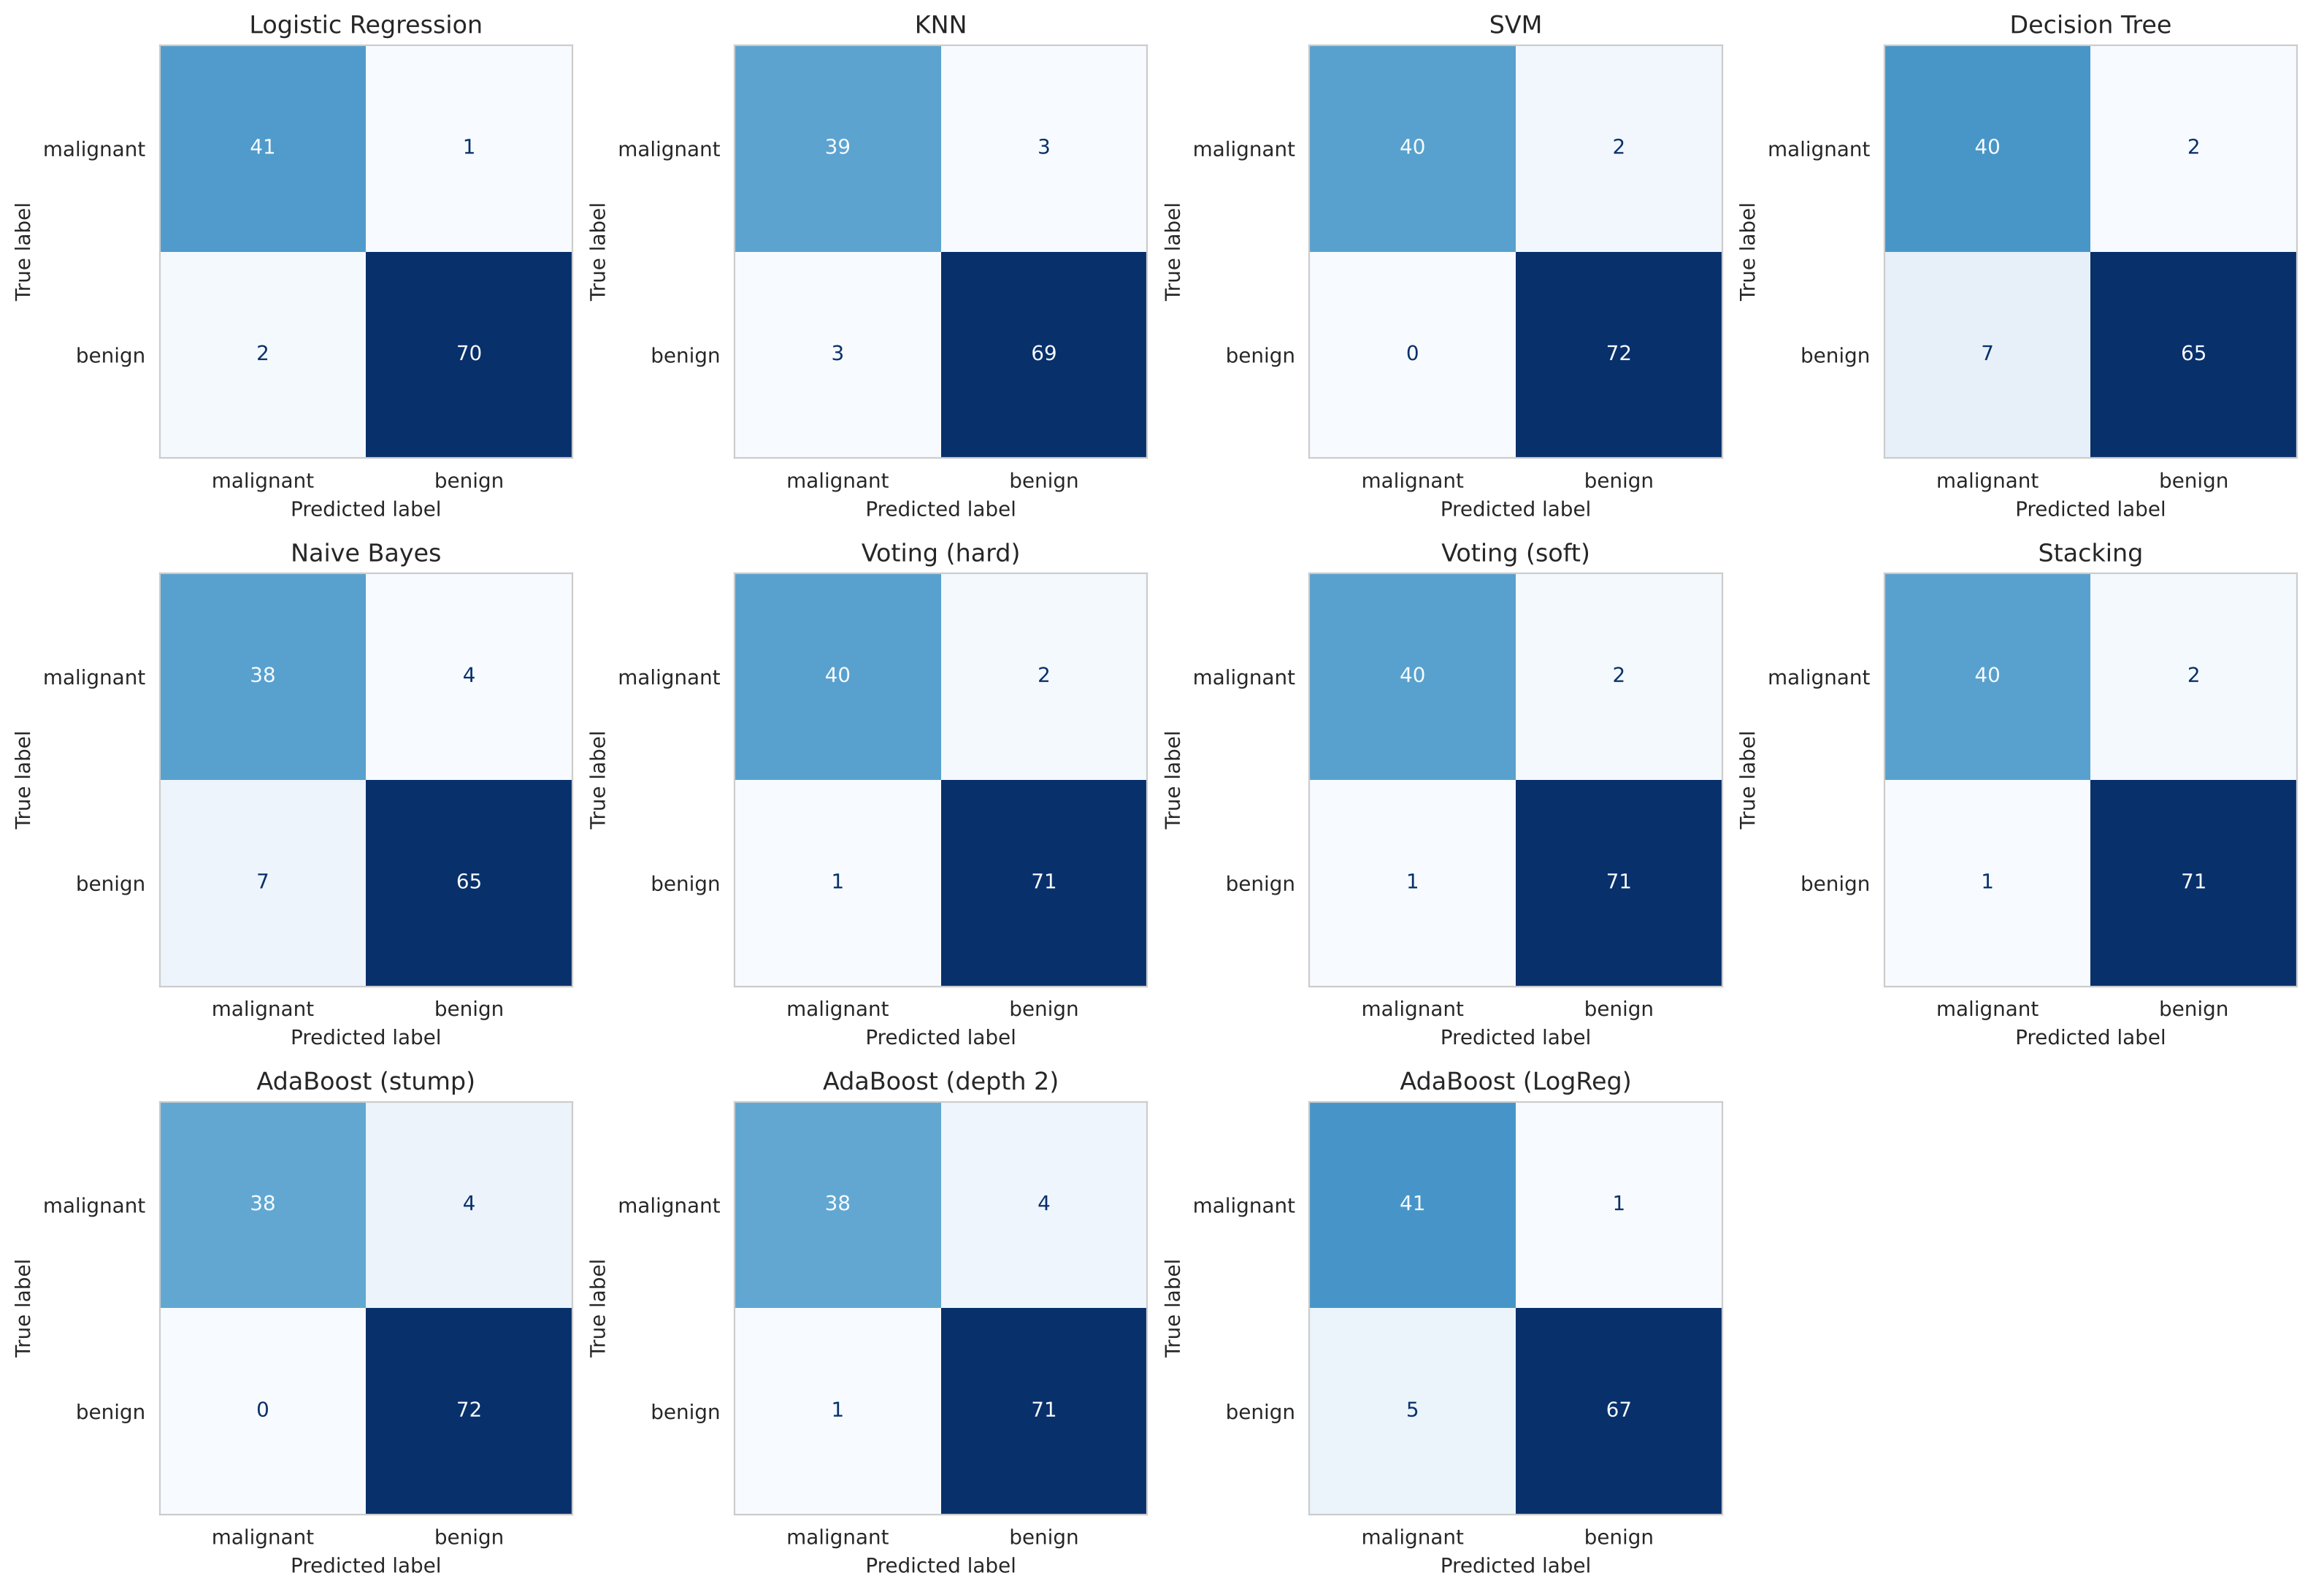

In [16]:
names = list(all_models)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, n in zip(axes.ravel(), names):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]),
                           display_labels=["malignant", "benign"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False); ax.set_title(n)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 6.2 ROC curves

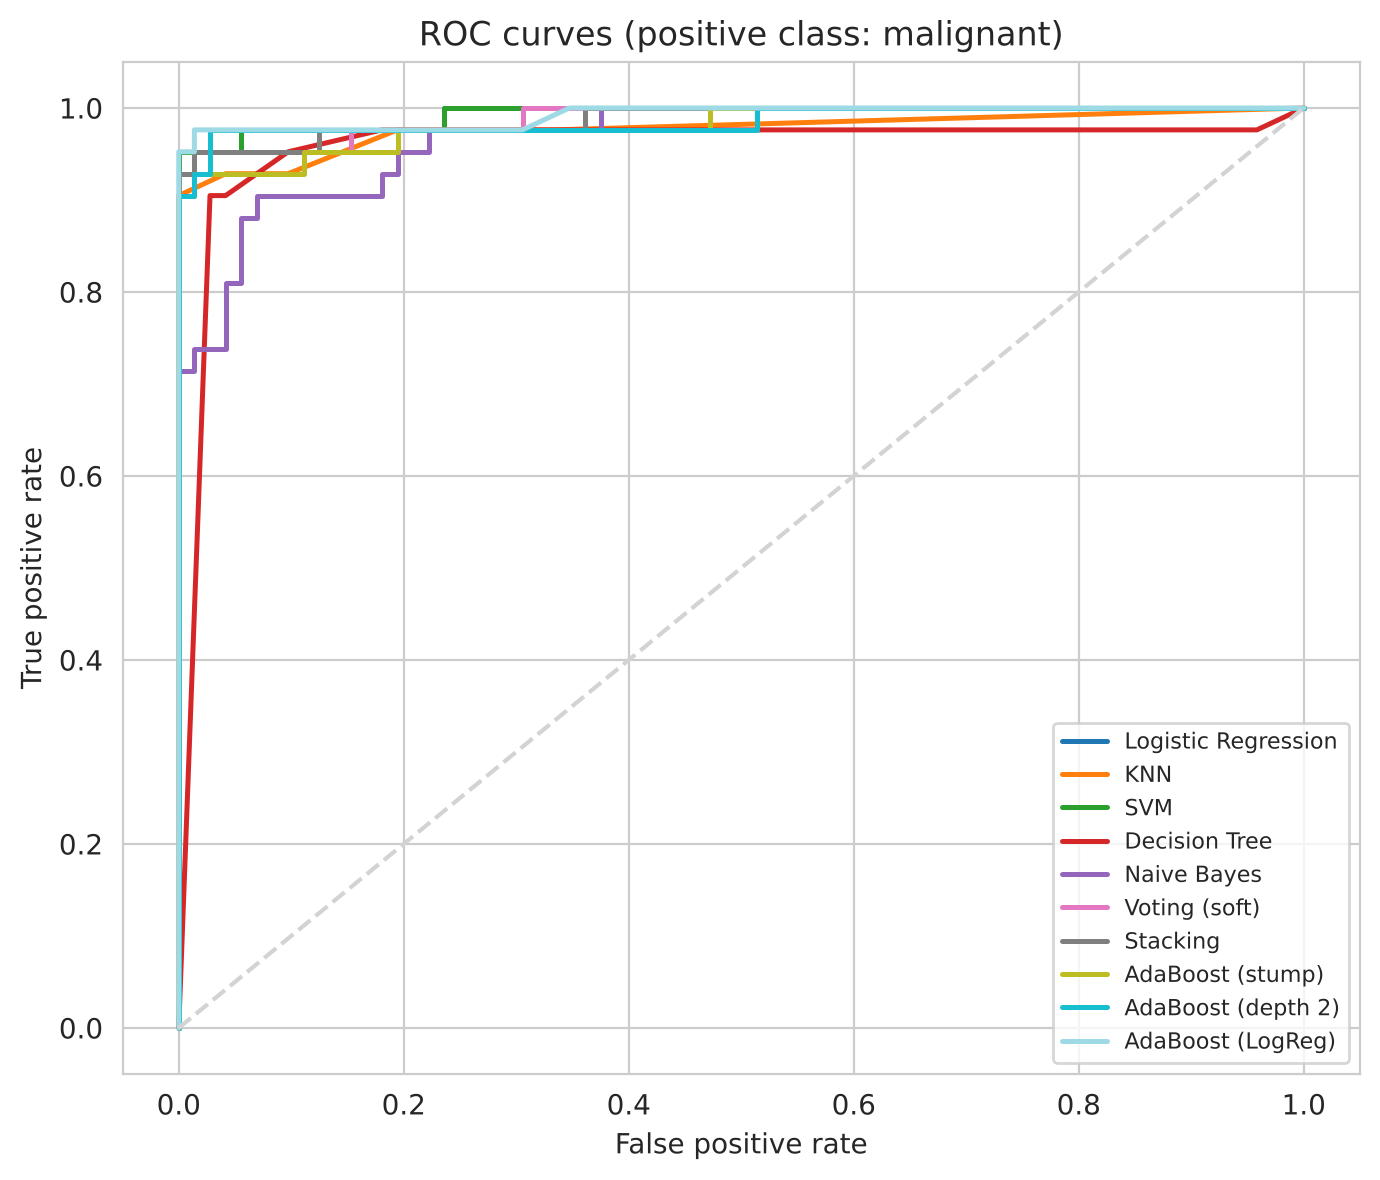

In [17]:
plt.figure(figsize=(7, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(names)))
for col, n in zip(colors, names):
    s = score_proba(fitted[n], X_test)
    if s is None: continue
    fpr, tpr, _ = roc_curve(1 - y_test, s)
    plt.plot(fpr, tpr, color=col, lw=1.8, label=n)
plt.plot([0, 1], [0, 1], color="lightgray", linestyle="--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (positive class: malignant)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Cross-validated comparison

A single 114-sample test set is small: one extra mistake changes accuracy by almost 1%. To get a fairer comparison, every model is also scored with **5-fold stratified cross-validation repeated 3 times (15 scores per model)** on the full preprocessed data. Scaling sits inside each pipeline, so there is no leakage.

In [18]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
from sklearn.metrics import make_scorer
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=0),
    "recall": make_scorer(recall_score, pos_label=0),
    "f1": make_scorer(f1_score, pos_label=0),
}

cv_rows, cv_acc = [], {}
for name, model in all_models.items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_acc[name] = res["test_accuracy"]
    cv_rows.append({"Model": name,
                    "Accuracy": res["test_accuracy"].mean(), "Acc. std": res["test_accuracy"].std(),
                    "Precision": res["test_precision"].mean(),
                    "Recall": res["test_recall"].mean(),
                    "F1": res["test_f1"].mean()})

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4).sort_values("F1", ascending=False)
cv_results

,Accuracy,Acc. std,Precision,Recall,F1
Model,,,,,
SVM,0.9742,0.0113,0.9840,0.9466,0.9648
Logistic Regression,0.9736,0.0115,0.9793,0.9497,0.9641
Voting (hard),0.9713,0.0126,0.9806,0.9419,0.9607
Stacking,0.9707,0.0094,0.9763,0.9450,0.9600
AdaBoost (stump),0.9678,0.0122,0.9659,0.9482,0.9564
AdaBoost (depth 2),0.9672,0.0149,0.9630,0.9497,0.9557
Voting (soft),0.9655,0.0122,0.9670,0.9403,0.9530
AdaBoost (LogReg),0.9572,0.0215,0.9413,0.9465,0.9433
KNN,0.9520,0.0186,0.9603,0.9105,0.9342


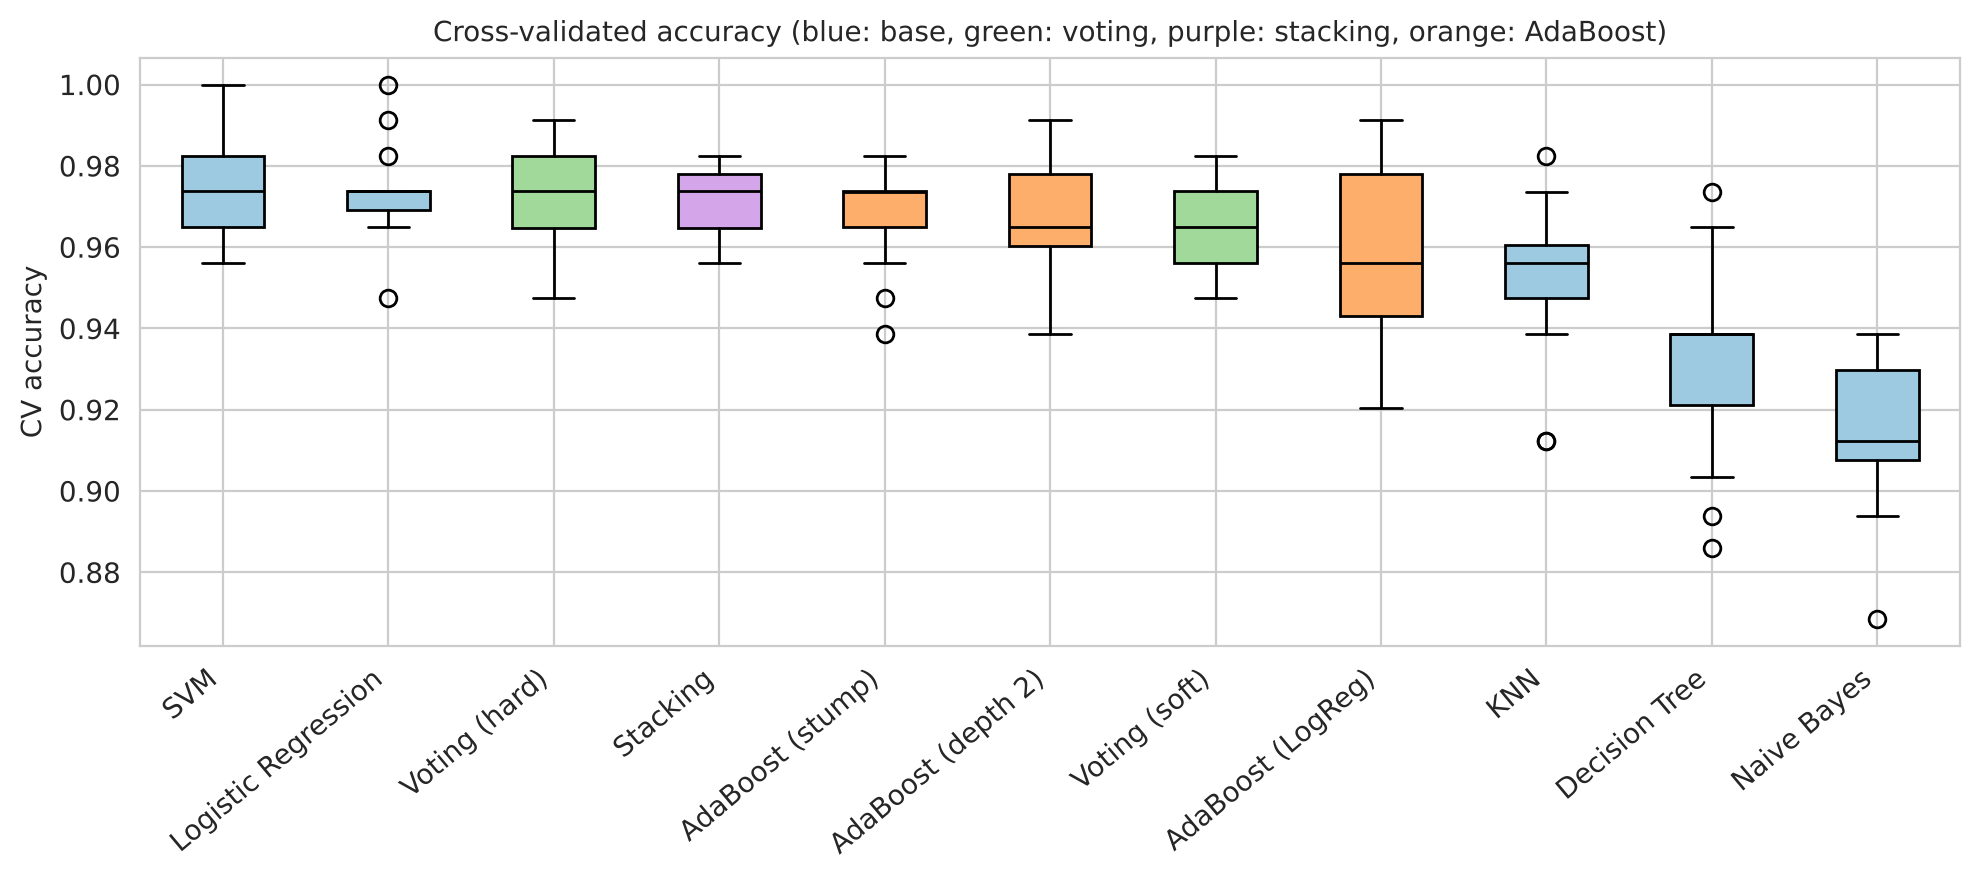

In [19]:
order = cv_results.index.tolist()
plt.figure(figsize=(10, 4.5))
bp = plt.boxplot([cv_acc[n] for n in order], vert=True, patch_artist=True,
                 medianprops=dict(color="black"))
for patch, n in zip(bp["boxes"], order):
    patch.set_facecolor("#9ecae1" if n in base_models else "#a1d99b" if n.startswith("Voting")
                        else "#fdae6b" if n.startswith("AdaBoost") else "#d4a5e8")
plt.xticks(range(1, len(order) + 1), order, rotation=40, ha="right"); plt.ylabel("CV accuracy")
plt.title("Cross-validated accuracy (blue: base, green: voting, purple: stacking, orange: AdaBoost)", fontsize=10); plt.tight_layout(); plt.show()

## 8. Do the ensembles actually beat the best single model?
The gap between models is small, so it helps to check whether it is larger than the fold to fold noise.

In [20]:
best_base = cv_results.loc[list(base_models)].sort_values("Accuracy", ascending=False).index[0]
print("Best base model by CV accuracy:", best_base, round(cv_acc[best_base].mean(), 4))
for n in ["Voting (hard)", "Voting (soft)", "Stacking", "AdaBoost (stump)", "AdaBoost (depth 2)", "AdaBoost (LogReg)"]:
    diff = cv_acc[n] - cv_acc[best_base]
    print(f"{n:20s} mean diff = {diff.mean():+.4f}   wins/ties/losses over {len(diff)} folds: "
          f"{(diff>0).sum()}/{(diff==0).sum()}/{(diff<0).sum()}   (fold std of diff = {diff.std():.4f})")

Best base model by CV accuracy: SVM 0.9742
Voting (hard)        mean diff = -0.0029   wins/ties/losses over 15 folds: 2/8/5   (fold std of diff = 0.0083)
Voting (soft)        mean diff = -0.0088   wins/ties/losses over 15 folds: 1/5/9   (fold std of diff = 0.0132)
Stacking             mean diff = -0.0035   wins/ties/losses over 15 folds: 3/6/6   (fold std of diff = 0.0095)
AdaBoost (stump)     mean diff = -0.0064   wins/ties/losses over 15 folds: 4/4/7   (fold std of diff = 0.0155)
AdaBoost (depth 2)   mean diff = -0.0070   wins/ties/losses over 15 folds: 4/3/8   (fold std of diff = 0.0173)
AdaBoost (LogReg)    mean diff = -0.0170   wins/ties/losses over 15 folds: 3/1/11   (fold std of diff = 0.0226)


## 9. Model diversity (why voting and stacking can help)
Ensembles gain from members that make *different* mistakes. The table below shows how often pairs of base models disagree on the test set.

In [21]:
bn = list(base_models)
dis = pd.DataFrame(index=bn, columns=bn, dtype=float)
for a in bn:
    for b in bn:
        dis.loc[a, b] = (preds[a] != preds[b]).mean()
dis.round(3)

,Logistic Regression,KNN,SVM,Decision Tree,Naive Bayes
Logistic Regression,0.000,0.061,0.026,0.053,0.088
KNN,0.061,0.000,0.035,0.096,0.061
SVM,0.026,0.035,0.000,0.061,0.079
Decision Tree,0.053,0.096,0.061,0.000,0.088
Naive Bayes,0.088,0.061,0.079,0.088,0.000


In [22]:
wrong = pd.DataFrame({n: preds[n] != y_test.values for n in bn})
print("Test samples misclassified by at least one base model:", int(wrong.any(axis=1).sum()))
print("Test samples misclassified by every base model       :", int(wrong.all(axis=1).sum()))
print("Stacking test errors:", int((preds['Stacking'] != y_test.values).sum()),
      "| Voting (hard) test errors:", int((preds['Voting (hard)'] != y_test.values).sum()))

Test samples misclassified by at least one base model: 16
Test samples misclassified by every base model       : 1
Stacking test errors: 3 | Voting (hard) test errors: 3


## 10. Classification report of the final candidates

In [23]:
for n in ["Stacking", "Voting (soft)", "AdaBoost (stump)"]:
    print("=" * 60); print(n); print("=" * 60)
    print(classification_report(y_test, preds[n], target_names=["malignant", "benign"], digits=3))

Stacking
              precision    recall  f1-score   support

   malignant      0.976     0.952     0.964        42
      benign      0.973     0.986     0.979        72

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114

Voting (soft)
              precision    recall  f1-score   support

   malignant      0.976     0.952     0.964        42
      benign      0.973     0.986     0.979        72

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114

AdaBoost (stump)
              precision    recall  f1-score   support

   malignant      1.000     0.905     0.950        42
      benign      0.947     1.000     0.973        72

    accuracy                          0.965       114
   macro avg      0.974     0.952     0.961       114
weighted avg      0.967     0.965 